In [1]:
!pip -q install graphviz
!apt-get -qq install graphviz

In [2]:
from collections import deque
from graphviz import Digraph
from IPython.display import display, SVG

In [3]:
EPS = 'ε'


def normalize_regex(regex):
    return regex.replace(' ', '').replace('/', '|')


def insert_concat(regex):
    regex = normalize_regex(regex)

    def is_literal(c):
        return c not in {'(', ')', '|', '*', '.'}

    def can_end(c):
        return is_literal(c) or c in {')', '*'}

    def can_start(c):
        return is_literal(c) or c == '('

    result = []

    for i, c in enumerate(regex):
        result.append(c)

        if i + 1 < len(regex):
            next_c = regex[i + 1]

            if can_end(c) and can_start(next_c):
                result.append('.')

    return ''.join(result)


def to_postfix(regex):
    infix = insert_concat(regex)

    precedence = {
        '|': 1,
        '.': 2,
        '*': 3
    }

    output = []
    operators = []

    for c in infix:

        if c not in precedence and c not in {'(', ')'}:
            output.append(c)

        elif c == '(':
            operators.append(c)

        elif c == ')':

            while operators and operators[-1] != '(':
                output.append(operators.pop())

            if not operators:
                raise ValueError("Mismatched parentheses")

            operators.pop()

        elif c in precedence:

            if c == '*':

                while (
                    operators
                    and operators[-1] != '('
                    and precedence[operators[-1]] > precedence[c]
                ):
                    output.append(operators.pop())

            else:

                while (
                    operators
                    and operators[-1] != '('
                    and precedence[operators[-1]] >= precedence[c]
                ):
                    output.append(operators.pop())

            operators.append(c)

    while operators:

        if operators[-1] in {'(', ')'}:
            raise ValueError("Mismatched parentheses")

        output.append(operators.pop())

    return ''.join(output)

In [4]:
def thompson_construction(regex):

    postfix = to_postfix(regex)

    transitions = {}

    next_state = 0

    def new_state():
        nonlocal next_state

        state = next_state
        next_state += 1

        transitions.setdefault(state, {})

        return state

    def add_transition(source, symbol, destination):

        transitions.setdefault(source, {})
        transitions.setdefault(destination, {})

        transitions[source].setdefault(symbol, set()).add(destination)

    stack = []

    for token in postfix:

        # Concatenation
        if token == '.':

            right = stack.pop()
            left = stack.pop()

            right_start, right_end = right
            left_start, left_end = left

            # Merge right_start into left_end
            outgoing = {
                symbol: set(states)
                for symbol, states in transitions.get(right_start, {}).items()
            }

            for source, symbol_map in list(transitions.items()):

                for symbol, states in symbol_map.items():

                    if right_start in states:

                        states.remove(right_start)
                        states.add(left_end)

            for symbol, states in outgoing.items():

                transitions.setdefault(left_end, {})
                transitions[left_end].setdefault(symbol, set()).update(states)

            transitions.pop(right_start, None)

            stack.append((left_start, right_end))

        # Union
        elif token == '|':

            right = stack.pop()
            left = stack.pop()

            start = new_state()
            end = new_state()

            add_transition(start, EPS, left[0])
            add_transition(start, EPS, right[0])

            add_transition(left[1], EPS, end)
            add_transition(right[1], EPS, end)

            stack.append((start, end))

        # Kleene Star
        elif token == '*':

            fragment = stack.pop()

            start = new_state()
            end = new_state()

            add_transition(start, EPS, fragment[0])
            add_transition(start, EPS, end)

            add_transition(fragment[1], EPS, fragment[0])
            add_transition(fragment[1], EPS, end)

            stack.append((start, end))

        # Basic symbol
        else:

            start = new_state()
            end = new_state()

            add_transition(start, token, end)

            stack.append((start, end))

    if len(stack) != 1:
        raise ValueError("Invalid regular expression")

    start, final = stack.pop()

    # Renumber states from the start state
    # This gives clean state numbers 0,1,2,...
    order = []

    visited = {start}

    queue = deque([start])

    while queue:

        current = queue.popleft()

        order.append(current)

        symbol_map = transitions.get(current, {})

        symbols = sorted(
            symbol_map.keys(),
            key=lambda x: (x != EPS, x)
        )

        for symbol in symbols:

            for destination in sorted(symbol_map[symbol]):

                if destination not in visited:

                    visited.add(destination)
                    queue.append(destination)

    mapping = {
        old: new
        for new, old in enumerate(order)
    }

    new_transitions = {}

    for old_state in order:

        new_state_number = mapping[old_state]

        new_transitions[new_state_number] = {}

        for symbol, destinations in transitions.get(old_state, {}).items():

            new_destinations = {
                mapping[destination]
                for destination in destinations
            }

            new_transitions[new_state_number][symbol] = new_destinations

    new_start = mapping[start]
    new_final = mapping[final]

    return (
        new_start,
        new_final,
        new_transitions,
        len(order),
        postfix
    )

In [5]:
regex = "(a/b)*abb"

start, final, nfa, nfa_states, postfix = thompson_construction(regex)

print("Regular Expression :", regex)
print("Postfix Expression :", postfix)
print("Number of NFA states:", nfa_states)
print("Start State         :", start)
print("Final State         :", final)

Regular Expression : (a/b)*abb
Postfix Expression : ab|*a.b.b.
Number of NFA states: 11
Start State         : 0
Final State         : 10


In [6]:
def print_nfa_table(nfa, number_of_states):

    print("\nNFA TRANSITION TABLE")
    print("-" * 60)

    print(
        f"{'State':<10}"
        f"{'a':<10}"
        f"{'b':<10}"
        f"{'ε':<10}"
    )

    print("-" * 60)

    for state in range(number_of_states):

        a = sorted(nfa.get(state, {}).get('a', set()))
        b = sorted(nfa.get(state, {}).get('b', set()))
        e = sorted(nfa.get(state, {}).get(EPS, set()))

        a = ','.join(map(str, a)) if a else '-'
        b = ','.join(map(str, b)) if b else '-'
        e = ','.join(map(str, e)) if e else '-'

        print(
            f"{state:<10}"
            f"{a:<10}"
            f"{b:<10}"
            f"{e:<10}"
        )

    print("-" * 60)
    print("Start state =", start)
    print("Final state =", final)

In [7]:
print_nfa_table(nfa, nfa_states)


NFA TRANSITION TABLE
------------------------------------------------------------
State     a         b         ε         
------------------------------------------------------------
0         -         -         1,2       
1         -         -         3,4       
2         5         -         -         
3         6         -         -         
4         -         7         -         
5         -         8         -         
6         -         -         9         
7         -         -         9         
8         -         10        -         
9         -         -         1,2       
10        -         -         -         
------------------------------------------------------------
Start state = 0
Final state = 10


In [8]:
def draw_nfa(nfa, start, final, number_of_states):

    dot = Digraph("NFA")

    dot.attr(rankdir="LR")

    dot.node("start", "", shape="point")

    for state in range(number_of_states):

        if state == final:

            dot.node(
                str(state),
                str(state),
                shape="doublecircle"
            )

        else:

            dot.node(
                str(state),
                str(state),
                shape="circle"
            )

    dot.edge("start", str(start))

    for source, symbol_map in nfa.items():

        for symbol, destinations in symbol_map.items():

            for destination in destinations:

                dot.edge(
                    str(source),
                    str(destination),
                    label=symbol
                )

    display(SVG(dot.pipe(format="svg")))

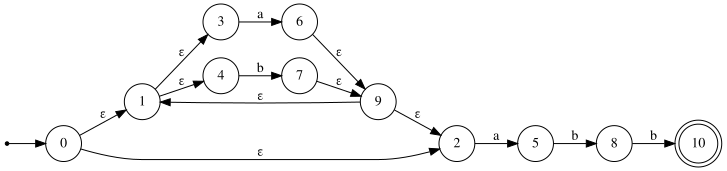

In [9]:
draw_nfa(
    nfa,
    start,
    final,
    nfa_states
)

In [10]:
def epsilon_closure(states, nfa):

    closure = set(states)

    stack = list(states)

    while stack:

        state = stack.pop()

        for destination in nfa.get(state, {}).get(EPS, set()):

            if destination not in closure:

                closure.add(destination)

                stack.append(destination)

    return frozenset(closure)

In [11]:
def move(states, symbol, nfa):

    result = set()

    for state in states:

        destinations = (
            nfa
            .get(state, {})
            .get(symbol, set())
        )

        result.update(destinations)

    return result

In [12]:
def subset_construction(
    nfa_start,
    nfa_final,
    nfa,
    alphabet
):

    start_set = epsilon_closure(
        {nfa_start},
        nfa
    )

    dfa_states = [start_set]

    state_number = {
        start_set: 0
    }

    dfa_transitions = {}

    queue = deque([start_set])

    while queue:

        current = queue.popleft()

        current_number = state_number[current]

        dfa_transitions[current_number] = {}

        for symbol in alphabet:

            moved = move(
                current,
                symbol,
                nfa
            )

            new_set = epsilon_closure(
                moved,
                nfa
            )

            if new_set not in state_number:

                new_number = len(dfa_states)

                state_number[new_set] = new_number

                dfa_states.append(new_set)

                queue.append(new_set)

            dfa_transitions[current_number][symbol] = (
                state_number[new_set]
            )

    accepting_states = set()

    for number, state_set in enumerate(dfa_states):

        if nfa_final in state_set:

            accepting_states.add(number)

    return (
        dfa_states,
        dfa_transitions,
        0,
        accepting_states
    )

In [13]:
alphabet = ['a', 'b']

dfa_states, dfa, dfa_start, dfa_final = subset_construction(
    start,
    final,
    nfa,
    alphabet
)

print("Number of DFA states:", len(dfa_states))
print("DFA start state:", dfa_start)
print("DFA final states:", dfa_final)

Number of DFA states: 5
DFA start state: 0
DFA final states: {4}


In [14]:
def print_dfa_table(
    dfa_states,
    dfa,
    dfa_start,
    dfa_final
):

    print("\nDFA SUBSET CONSTRUCTION")
    print("-" * 70)

    for i, state_set in enumerate(dfa_states):

        name = f"A{i}"

        print(
            f"{name} = "
            f"{{{', '.join(map(str, sorted(state_set)))}}}"
        )

    print("\nDFA TRANSITION TABLE")
    print("-" * 50)

    print(
        f"{'State':<10}"
        f"{'a':<10}"
        f"{'b':<10}"
        f"{'Final?':<10}"
    )

    print("-" * 50)

    for state in range(len(dfa_states)):

        print(
            f"A{state:<9}"
            f"A{dfa[state]['a']:<9}"
            f"A{dfa[state]['b']:<9}"
            f"{'YES' if state in dfa_final else 'NO':<10}"
        )

    print("-" * 50)

In [15]:
print_dfa_table(
    dfa_states,
    dfa,
    dfa_start,
    dfa_final
)


DFA SUBSET CONSTRUCTION
----------------------------------------------------------------------
A0 = {0, 1, 2, 3, 4}
A1 = {1, 2, 3, 4, 5, 6, 9}
A2 = {1, 2, 3, 4, 7, 9}
A3 = {1, 2, 3, 4, 7, 8, 9}
A4 = {1, 2, 3, 4, 7, 9, 10}

DFA TRANSITION TABLE
--------------------------------------------------
State     a         b         Final?    
--------------------------------------------------
A0        A1        A2        NO        
A1        A1        A3        NO        
A2        A1        A2        NO        
A3        A1        A4        NO        
A4        A1        A2        YES       
--------------------------------------------------


In [16]:
def draw_dfa(
    dfa_states,
    dfa,
    dfa_start,
    dfa_final
):

    dot = Digraph("DFA")

    dot.attr(rankdir="LR")

    dot.node("start", "", shape="point")

    for state in range(len(dfa_states)):

        label = f"A{state}"

        if state in dfa_final:

            dot.node(
                label,
                label,
                shape="doublecircle"
            )

        else:

            dot.node(
                label,
                label,
                shape="circle"
            )

    dot.edge(
        "start",
        f"A{dfa_start}"
    )

    for source, transitions in dfa.items():

        for symbol, destination in transitions.items():

            dot.edge(
                f"A{source}",
                f"A{destination}",
                label=symbol
            )

    display(SVG(dot.pipe(format="svg")))

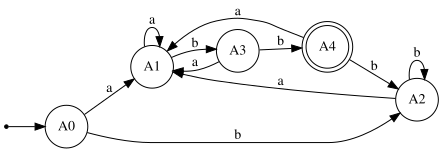

In [17]:
draw_dfa(
    dfa_states,
    dfa,
    dfa_start,
    dfa_final
)

In [18]:
def minimize_dfa(
    dfa,
    start,
    final_states,
    alphabet
):

    number_of_states = len(dfa)

    transitions = {}

    for state in range(number_of_states):

        transitions[state] = {}

        for symbol in alphabet:

            transitions[state][symbol] = (
                dfa[state].get(symbol)
            )

    # Create dead state if a transition is missing

    needs_dead_state = any(
        transitions[state][symbol] is None
        for state in transitions
        for symbol in alphabet
    )

    if needs_dead_state:

        dead = number_of_states

        transitions[dead] = {
            symbol: dead
            for symbol in alphabet
        }

        for state in range(number_of_states):

            for symbol in alphabet:

                if transitions[state][symbol] is None:

                    transitions[state][symbol] = dead

        total_states = number_of_states + 1

    else:

        total_states = number_of_states

    final_states = set(final_states)

    non_final_states = (
        set(range(total_states))
        - final_states
    )

    partitions = []

    if final_states:
        partitions.append(final_states)

    if non_final_states:
        partitions.append(non_final_states)

    changed = True

    while changed:

        changed = False

        block_id = {}

        for i, block in enumerate(partitions):

            for state in block:

                block_id[state] = i

        new_partitions = []

        for block in partitions:

            groups = {}

            for state in block:

                signature = tuple(
                    block_id[
                        transitions[state][symbol]
                    ]
                    for symbol in alphabet
                )

                groups.setdefault(
                    signature,
                    set()
                ).add(state)

            new_partitions.extend(
                groups.values()
            )

            if len(groups) > 1:

                changed = True

        partitions = new_partitions

    block_id = {}

    for i, block in enumerate(partitions):

        for state in block:

            block_id[state] = i

    minimized = {}

    for i, block in enumerate(partitions):

        representative = next(iter(block))

        minimized[i] = {}

        for symbol in alphabet:

            minimized[i][symbol] = (
                block_id[
                    transitions[
                        representative
                    ][symbol]
                ]
            )

    minimized_start = block_id[start]

    minimized_final = {
        block_id[state]
        for state in final_states
    }

    return (
        minimized,
        minimized_start,
        minimized_final,
        partitions
    )

In [19]:
min_dfa, min_start, min_final, partitions = minimize_dfa(
    dfa,
    dfa_start,
    dfa_final,
    alphabet
)

print("MINIMIZED DFA")
print("-" * 50)

print("Number of minimized states:", len(min_dfa))
print("Start state:", min_start)
print("Final states:", min_final)

print("\nPartitions:")
for i, partition in enumerate(partitions):
    print(f"Q{i} =", sorted(partition))

MINIMIZED DFA
--------------------------------------------------
Number of minimized states: 4
Start state: 1
Final states: {0}

Partitions:
Q0 = [4]
Q1 = [0, 2]
Q2 = [1]
Q3 = [3]


In [20]:
def print_minimized_dfa(
    min_dfa,
    min_start,
    min_final
):

    print("\nMINIMIZED DFA TRANSITION TABLE")
    print("-" * 50)

    print(
        f"{'State':<10}"
        f"{'a':<10}"
        f"{'b':<10}"
        f"{'Final?':<10}"
    )

    print("-" * 50)

    for state in sorted(min_dfa):

        print(
            f"Q{state:<9}"
            f"Q{min_dfa[state]['a']:<9}"
            f"Q{min_dfa[state]['b']:<9}"
            f"{'YES' if state in min_final else 'NO':<10}"
        )

    print("-" * 50)

In [21]:
print_minimized_dfa(
    min_dfa,
    min_start,
    min_final
)


MINIMIZED DFA TRANSITION TABLE
--------------------------------------------------
State     a         b         Final?    
--------------------------------------------------
Q0        Q2        Q1        YES       
Q1        Q2        Q1        NO        
Q2        Q2        Q3        NO        
Q3        Q2        Q0        NO        
--------------------------------------------------


In [22]:
def draw_minimized_dfa(
    min_dfa,
    min_start,
    min_final
):

    dot = Digraph("Minimized_DFA")

    dot.attr(rankdir="LR")

    dot.node(
        "start",
        "",
        shape="point"
    )

    for state in sorted(min_dfa):

        label = f"Q{state}"

        if state in min_final:

            dot.node(
                label,
                label,
                shape="doublecircle"
            )

        else:

            dot.node(
                label,
                label,
                shape="circle"
            )

    dot.edge(
        "start",
        f"Q{min_start}"
    )

    for source, transitions in min_dfa.items():

        for symbol, destination in transitions.items():

            dot.edge(
                f"Q{source}",
                f"Q{destination}",
                label=symbol
            )

    display(
        SVG(
            dot.pipe(
                format="svg"
            )
        )
    )

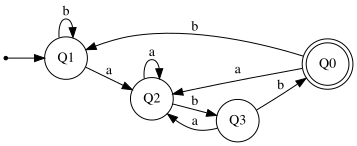

In [23]:
draw_minimized_dfa(
    min_dfa,
    min_start,
    min_final
)

In [24]:
def test_string(
    string,
    dfa,
    start,
    final_states,
    alphabet
):

    current = start

    for char in string:

        if char not in alphabet:

            return False

        current = dfa[current][char]

    return current in final_states

In [25]:
test_cases = [
    "abb",
    "aabb",
    "babb",
    "ababb",
    "bababb",
    "abba",
    "aba",
    "bab",
    "aa",
    ""
]

print("STRING TESTING")
print("-" * 40)

for string in test_cases:

    accepted = test_string(
        string,
        min_dfa,
        min_start,
        min_final,
        alphabet
    )

    result = "Accept" if accepted else "Not Accepted"

    display_string = string if string else "ε"

    print(
        f"{display_string:<10} -> {result}"
    )

STRING TESTING
----------------------------------------
abb        -> Accept
aabb       -> Accept
babb       -> Accept
ababb      -> Accept
bababb     -> Accept
abba       -> Not Accepted
aba        -> Not Accepted
bab        -> Not Accepted
aa         -> Not Accepted
ε          -> Not Accepted


REGULAR EXPRESSION TO MINIMIZED DFA
Enter Regular Expression (example: (a/b)*abb): (a/b)*abb

Regular Expression: (a/b)*abb
Postfix: ab|*a.b.b.
NFA States: 11
NFA Start: 0
NFA Final: 10

NFA TRANSITION TABLE
------------------------------------------------------------
State     a         b         ε         
------------------------------------------------------------
0         -         -         1,2       
1         -         -         3,4       
2         5         -         -         
3         6         -         -         
4         -         7         -         
5         -         8         -         
6         -         -         9         
7         -         -         9         
8         -         10        -         
9         -         -         1,2       
10        -         -         -         
------------------------------------------------------------
Start state = 0
Final state = 10

Generating DFA...
Number of DFA states: 5

DFA SUBSET CONSTRUCTION
----------------

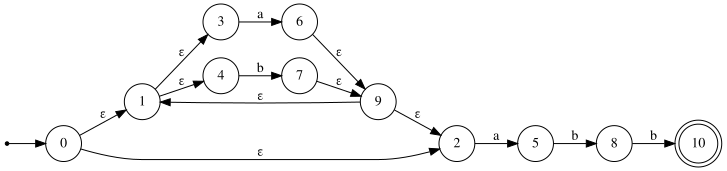


DFA:


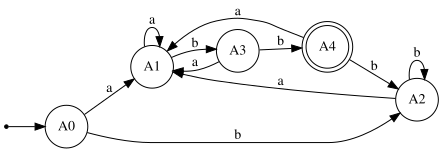


MINIMIZED DFA:


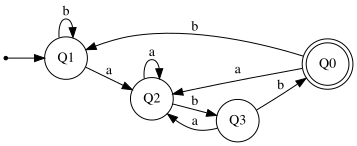


Testing strings

Enter string (type STOP to finish): (a|b)*abb
Not Accepted

Enter string (type STOP to finish): abb
Accept

Enter string (type STOP to finish): abba
Not Accepted

Enter string (type STOP to finish): STOP


In [26]:
print("=" * 60)
print("REGULAR EXPRESSION TO MINIMIZED DFA")
print("=" * 60)

regex = input(
    "Enter Regular Expression "
    "(example: (a/b)*abb): "
).strip()

try:

    start, final, nfa, nfa_states, postfix = (
        thompson_construction(regex)
    )

    alphabet = sorted(
        {
            symbol
            for transitions in nfa.values()
            for symbol in transitions
            if symbol != EPS
        }
    )

    print("\nRegular Expression:", regex)
    print("Postfix:", postfix)
    print("NFA States:", nfa_states)
    print("NFA Start:", start)
    print("NFA Final:", final)

    print_nfa_table(
        nfa,
        nfa_states
    )

    print("\nGenerating DFA...")

    dfa_states, dfa, dfa_start, dfa_final = (
        subset_construction(
            start,
            final,
            nfa,
            alphabet
        )
    )

    print(
        "Number of DFA states:",
        len(dfa_states)
    )

    print_dfa_table(
        dfa_states,
        dfa,
        dfa_start,
        dfa_final
    )

    print("\nMinimizing DFA...")

    min_dfa, min_start, min_final, partitions = (
        minimize_dfa(
            dfa,
            dfa_start,
            dfa_final,
            alphabet
        )
    )

    print(
        "Number of minimized DFA states:",
        len(min_dfa)
    )

    print_minimized_dfa(
        min_dfa,
        min_start,
        min_final
    )

    print("\nAutomata diagrams:")

    print("\nNFA:")
    draw_nfa(
        nfa,
        start,
        final,
        nfa_states
    )

    print("\nDFA:")
    draw_dfa(
        dfa_states,
        dfa,
        dfa_start,
        dfa_final
    )

    print("\nMINIMIZED DFA:")
    draw_minimized_dfa(
        min_dfa,
        min_start,
        min_final
    )

    print("\nTesting strings")

    while True:

        string = input(
            "\nEnter string "
            "(type STOP to finish): "
        )

        if string.upper() == "STOP":
            break

        accepted = test_string(
            string,
            min_dfa,
            min_start,
            min_final,
            alphabet
        )

        if accepted:
            print("Accept")
        else:
            print("Not Accepted")

except Exception as error:

    print("\nError:", error)